In [1]:
%load_ext autoreload
%autoreload 2

In [28]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

from dotenv import dotenv_values
from matplotlib import pyplot as plt

In [3]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Plotting defaults
MM = 1/25.4
RCPARAMS = '../../../resources/figures.mplstyle'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'sexual_dimorphism'
FIGUREDIR = DATADIR / 'publication' / 'Ext_Fig_09'
FIGUREDIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Load cell-type sexual dimorphism metrics
fp_sd_metrics = OUTDIR / 'L4_sd_metrics.csv'
df_sd_metrics = pd.read_csv(fp_sd_metrics, index_col=0)
df_sd_metrics.head(3)

,n_DEGs,pct_Female,sLISI_Q1,sLISI_Q2,sLISI_Q3,sex_ratio_deviance
celltype_ID,,,,,,
Gl4-220,561,0.325898,0.310767,0.808747,0.981644,0.174102
Gl4-140,539,0.409053,0.545246,0.877870,0.982116,0.090947
Gb4-438,409,0.333582,0.358622,0.733945,0.923493,0.166418


### Subplot C: most dimorphic regions

In [7]:
# Extract all sexually dimorphic populations
N_SIG_GENES_THRESHOLD = 100

df_sd_metrics['is_dimorphic'] = (
    (df_sd_metrics['n_DEGs'] >= N_SIG_GENES_THRESHOLD)
    | (df_sd_metrics['pct_Female'] >= 0.95)
    | (df_sd_metrics['pct_Female'] <= 0.05)
)

sd_celltypes = df_sd_metrics[df_sd_metrics['is_dimorphic']].index.tolist()

In [53]:
# Load region relmass table
fp_region_table = DATADIR / '9_objects' / 'spatial' / 'regionwise_relative_masses' / 'regionwise_relative_masses_wo_fibers_or_non_HY_regions.csv'
df_region_table = pd.read_csv(fp_region_table, index_col=0)
df_region_table.drop(columns=['celltype_descr', 'celltype_abc_like', 'flag'], inplace=True)
df_region_table

,TMv,PVa,PVH,PVHd,ADP,AHN,PVi,PVp,PVpo,RCH,...,HY,PS,TMd,ME,VMPO,PeF,MMl,MMm,MMp,MMd
celltype_id,,,,,,,,,,,,,,,,,,,,,
Gb1-2,0.006751,0.007684,0.006426,0.009450,0.011216,0.058012,0.010843,0.010975,0.019578,0.008290,...,0.188627,0.012184,0.002222,0.007548,0.005155,0.012813,0.000732,0.000384,0.000079,0.000775
Gl1-1,0.003459,0.002353,0.023333,0.006919,0.003396,0.039845,0.010897,0.009214,0.012308,0.006636,...,0.162567,0.001840,0.004350,0.003064,0.002292,0.007933,0.030843,0.024505,0.006384,0.009122
NN1-1,0.003236,0.001543,0.005688,0.008262,0.006640,0.039844,0.006289,0.003013,0.005629,0.010631,...,0.193250,0.003886,0.000931,0.002591,0.002832,0.021743,0.008567,0.004741,0.001156,0.002827
NN1-2,0.002935,0.004189,0.021761,0.012229,0.009201,0.060077,0.009094,0.004104,0.011354,0.009444,...,0.191273,0.009402,0.000389,0.006105,0.003450,0.015942,0.004506,0.003004,0.001826,0.002342
NN1-3,0.019835,0.002536,0.017493,0.008756,0.005271,0.032650,0.008483,0.007614,0.008535,0.006460,...,0.166561,0.005189,0.001709,0.013722,0.002015,0.011433,0.019457,0.010107,0.004931,0.015613
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NN5-42,0.001405,0.004001,0.007944,0.001671,0.000907,0.002492,0.208690,0.026532,0.098157,0.006628,...,0.084057,0.000286,0.008178,0.026277,0.001101,0.000651,0.002457,0.001873,0.000504,0.000875
NN5-43,0.001774,0.019744,0.024248,0.003223,0.000737,0.001928,0.274204,0.014994,0.134144,0.002753,...,0.102755,0.000101,0.009015,0.005437,0.000561,0.000258,0.002807,0.001781,0.000420,0.000189
NN5-44,0.000929,0.033086,0.046670,0.004919,0.000090,0.002177,0.170459,0.006192,0.263719,0.003961,...,0.148946,0.000018,0.003465,0.000242,0.000863,0.001255,0.001676,0.004257,0.000587,0.000472


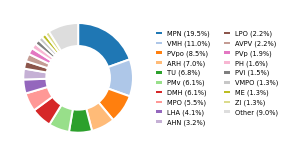

In [60]:
# Subset to only sd cell types
df_sd_region_table = df_region_table.loc[sd_celltypes]

# Sum probability mass per region
region_contribution = df_sd_region_table.sum(axis=0)
region_contribution /= region_contribution.sum()
region_contribution.sort_values(ascending=False).head(4)

# Drop HY region and renormalize region_contribution
region_contribution = region_contribution.drop("HY", errors="ignore")
region_contribution /= region_contribution.sum()

# remove regions < 0.01% and replace with `other`
region_contribution = region_contribution[region_contribution >= 0.01]
region_contribution['other'] = 1 - region_contribution.sum()

# Ensure "other" is last
region_contribution = (
    region_contribution
    .drop("other")
    .sort_values(ascending=False)
)
region_contribution["Other"] = 1 - region_contribution.sum()

colors = list(plt.cm.tab20.colors[:len(region_contribution)-1]) + ["#DDDDDD"]

plt.close('all')
with plt.style.context(RCPARAMS):
    fig, ax = plt.subplots(figsize=(70*MM, 50*MM))

    legend_labels = [
        f"{region} ({100 * frac:.1f}%)"
        for region, frac in region_contribution.items()
    ]

    wedges, _ = ax.pie(
        region_contribution,
        labels=None,
        colors=colors,
        startangle=90,
        counterclock=False,
        wedgeprops=dict(width=0.42, edgecolor="white", linewidth=1.5),
    )

    ax.legend(
        wedges,
        legend_labels,
        frameon=False,
        fontsize=5,
        bbox_to_anchor=(1.02, 0.5),
        loc="center left",
        handlelength=1.2,
        handletextpad=0.5,
        ncol=2,
    )

    ax.set(aspect="equal")
    
    fig.savefig(
        FIGUREDIR / "subplot_c_region_pie.pdf",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )
    
    plt.tight_layout()